# El protocolo a prueba de fuga por caso, con compuertas

**Pregunta:** Cuando una variable filtra el resultado al desarrollo, ¿qué pruebas de validación lo ven y con qué frecuencia, y cuánto protegen las divisiones declaradas de C01, C02 y C03 los ajustes del producto contra ello?

- **Nivel:** 4, métodos propuestos
- **Requisitos previos:** los notebooks 02 a 05 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook puedes:

- enunciar el protocolo a prueba de fuga de Contraste, las seis reglas que impone y la división que declara cada uno de los tres casos de puntuación de crédito;
- verificar en los artefactos versionados de C01, C02 y C03 lo que garantizan las puertas del protocolo, y ver al motor rechazar una añada cuyo objetivo aún no es observable;
- medir cómo se ve una filtración para las pruebas del motor, con una filtración plantada de tamaño conocido, por simulación y frente a la verdad exacta del generador;
- decir exactamente qué enuncia la afirmación y qué no: imposición de reglas conocidas mediante puertas, no un método nuevo.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La siguiente celda importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
import re
from datetime import date

from riskvalidation.generators.scores import BinormalScores
from riskvalidation.stress.paths import check_vintage
from riskvalidation.validation.discrimination import disc_auc, disc_auc_vs_initial
from riskvalidation.validation.stability import bin_counts, quantile_edges, stability_csi

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

El notebook lee la evidencia que lista la afirmación, y nada más:

- los requisitos y las puertas: `docs/design/features/c01-retail-pd/requirements.md` (los requisitos EARS CT-101 a CT-103, cada uno con la prueba que falla cuando se viola). Las puertas mismas están en `tests/test_leakage.py`; ejecutarlas requiere las bibliotecas de la cadena de cálculo, que el entorno de los notebooks no trae;
- la división declarada de cada caso, tal como está versionada: `data/derived/C01/models-taiwan.json` y `holdout.json`, `data/derived/C02/h1.json` a `h5.json` y `pooled.json`, `data/derived/C03/fy2015-17.json`, `fy2018-20.json` y `models-sba-7a.json`;
- la filtración plantada del caso C22: `data/derived/C22/leakage.json`, sintético con una verdad conocida (sin licencia de terceros; generado por el motor desde una semilla).

Los datos reales detrás de C01, C02 y C03 son el archivo de tarjetas de crédito de Taiwán de UCI (Yeh, 2009; CC BY 4.0; https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients), el archivo de empresas polacas de UCI (Tomczak, 2016; CC BY 4.0; https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data) y el archivo de créditos 7(a) de la SBA de EE. UU. (U.S. Government Works; https://data.sba.gov/dataset/7a-504-foia); los tres son `mirror-allowed`. La siguiente celda carga los archivos e imprime los tres requisitos con sus puertas y el límite que declara cada caso.

In [2]:
# Cargar la evidencia de la afirmación e imprimir sus puertas y los límites que declaran los artefactos
ROOT = Path("../../..").resolve()
names = ["C01/models-taiwan", "C01/holdout", "C22/leakage", "C03/models-sba-7a", "C03/fy2015-17", "C03/fy2018-20"]
names += [f"C02/{h}" for h in ("h1", "h2", "h3", "h4", "h5", "pooled")]
docs = {n: json.loads((ROOT / "data" / "derived" / f"{n}.json").read_text(encoding="utf-8")) for n in names}
c01, c01_holdout, c22 = docs["C01/models-taiwan"], docs["C01/holdout"], docs["C22/leakage"]
c02 = {h: docs[f"C02/{h}"] for h in ("h1", "h2", "h3", "h4", "h5", "pooled")}
c03_models = docs["C03/models-sba-7a"]
c03 = {n: docs[f"C03/{n}"] for n in ("fy2015-17", "fy2018-20")}
feature = ROOT / "docs" / "design" / "features" / "c01-retail-pd"
requirements = (feature / "requirements.md").read_text(encoding="utf-8")
policy = rv.default_policy()
LANG = "es"
LIGHT = {"green": "verde", "amber": "ámbar", "red": "roja", "not_evaluated": "ninguna"}
for line in requirements.splitlines():
    if re.match(r"\| CT-10[123] ", line):
        cells_ = [c.strip() for c in line.strip().strip("|").split("|")]
        print(cells_[0], cells_[2])
f_oot = next(f for f in c01_holdout["findings"] if f["id"] == "F-OOT")
f_data = next(f for f in c03["fy2015-17"]["findings"] if f["id"] == "F-DATA")
print("C01", f_oot["id"], "|", f_oot["title"][LANG])
print("C02 out_of_time_claim =", c02["h3"]["outputs"]["split"]["out_of_time_claim"])
print("C03", f_data["id"], "|", f_data["title"][LANG])
baked = c01_holdout["provenance"]["riskvalidation_version"]
print("calculado por riskvalidation", baked, "| instalado", rv.__version__)

CT-101 `tests/test_leakage.py::test_fitted_transforms_train_only`
CT-102 `tests/test_leakage.py::test_calibration_slice_disjoint`
CT-103 `tests/test_leakage.py::test_outside_information_perturbation_invariance`
C01 F-OOT | No es posible validar fuera del tiempo: los datos son una sola foto
C02 out_of_time_claim = False
C03 F-DATA | Créditos a pequeñas empresas SBA 7(a) bajo garantía federal, no la cartera pyme de un banco; sin mora, saldo ni calificación
calculado por riskvalidation 1.0.1 | instalado 1.0.1


## Método

### Paso 1: las reglas, los requisitos y las puertas

La base de investigación del producto (dossier 04, "reglas universales de fuga") enuncia seis reglas para toda cadena de puntuación:

1. toda variable se calcula con información disponible a la fecha de observación, y la ventana de desempeño comienza después de ella;
2. la agrupación en tramos, el WoE, la imputación, el escalamiento y la selección de variables se ajustan solo con la parte de entrenamiento;
3. los mapas de calibración se ajustan con una parte de calibración separada, nunca con la de prueba;
4. nada se remuestrea antes de medir la calibración;
5. para la pérdida dado el incumplimiento y los factores de conversión de crédito, el conjunto de entrenamiento contiene solo incumplimientos cuya ventana de recuperación o de referencia cerró antes de la fecha de corte del entrenamiento;
6. las covariables macro entran con el rezago con que estarían disponibles en tiempo real.

Las reglas 1 a 4 se aplican a los casos de puntuación (las reglas 5 y 6 pertenecen a los temas 05 y 12). Lo que el producto agrega es la segunda mitad de cada regla: un requisito en forma EARS (Mavin et al., 2009, https://doi.org/10.1109/RE.2009.9) que nombra **la puerta que falla cuando se viola la regla**. La celda de carga imprimió los requisitos CT-101, CT-102 y CT-103 con sus puertas: el ajuste usa solo la parte de entrenamiento, el mapa de calibración tiene su propia parte, y todo parámetro ajustado queda igual cuando se perturba un valor ajeno a la información de entrenamiento. Las puertas están en `tests/test_leakage.py` y ejecutan dos veces la ruta de ajuste del propio caso, una sobre un conjunto de datos plantado y otra con la muestra reservada y las entradas de calibración cambiadas; un parámetro ajustado que se mueve leyó algo que no debía. Requieren las bibliotecas de la cadena de cálculo, así que este notebook no puede ejecutarlas. Verifica, en los artefactos versionados, las propiedades que las puertas garantizan, caso por caso, empezando por C01: la celda dibuja las tres partes y el número de tarjetas detrás de cada una de las 13 variables agrupadas.

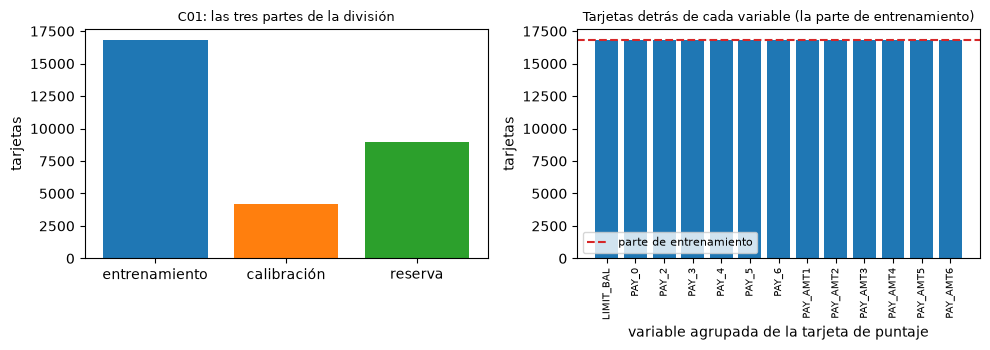

mapas de calibración y la parte con que se ajustó cada uno: [('P3-ebm', 'parte de calibración'), ('P4-lightgbm', 'parte de calibración'), ('P4-xgboost', 'parte de calibración')]
totales distintos detrás de las 13 variables: [16800]


In [3]:
# Las tres partes de la división de C01 y las tarjetas detrás de cada variable agrupada de la tarjeta de puntaje
split = c01["fit"]["split"]
card = next(m for m in c01["model"] if m["id"] == "P1-scorecard")["details"]
sums = {n: sum(r["count"] for r in card["points_table"] if r["feature"] == n) for n in card["features"]}
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
sizes = [split[k]["n"] for k in ("train", "calibration", "holdout")]
left.bar(["entrenamiento", "calibración", "reserva"], sizes, color=["tab:blue", "tab:orange", "tab:green"])
left.set_ylabel("tarjetas")
left.set_title("C01: las tres partes de la división", fontsize=9)
right.bar(list(sums), list(sums.values()), color="tab:blue")
right.axhline(split["train"]["n"], color="tab:red", linestyle="--", label="parte de entrenamiento")
right.tick_params(axis="x", labelrotation=90, labelsize=7)
right.set_xlabel("variable agrupada de la tarjeta de puntaje")
right.set_ylabel("tarjetas")
right.set_title("Tarjetas detrás de cada variable (la parte de entrenamiento)", fontsize=9)
right.legend(fontsize=8)
fig.tight_layout()
plt.show()
maps = [(m["id"], m["calibration"]["fitted_on"].replace("calibration slice", "parte de calibración"))
        for m in c01["model"] if m["calibration"] is not None]
print("mapas de calibración y la parte con que se ajustó cada uno:", maps)
print("totales distintos detrás de las 13 variables:", sorted(set(sums.values())))

Las tres partes dividen las 30.000 tarjetas del archivo en 16.800, 4.200 y 9.000, y los conteos detrás de cada una de las 13 variables agrupadas son un único total, 16.800: la agrupación vio la parte de entrenamiento y nada más. Los tres mapas de calibración (la máquina de refuerzo, LightGBM y XGBoost) se ajustaron con la parte de calibración. Estos son los hechos que garantizan CT-101 y CT-102, leídos del artefacto; la figura los muestra pero no puede mostrar el contrafactual, que un ajuste que espiara la muestra reservada daría conteos distintos.

### Paso 2: C02, marcas que rechazan una afirmación

Los archivos polacos no tienen fecha ni identificador de empresa, así que el protocolo de C02 es una muestra reservada bloqueada y estratificada dentro de cada archivo, y **rechaza las afirmaciones que los datos no pueden sustentar**. Se versionan cuatro marcas en el bloque de división de cada archivo de horizonte y del archivo agrupado: el ajuste usa solo la parte de entrenamiento, el mapa de calibración tiene su propia parte, nada se remuestrea antes de calibrar, y no se hace ninguna afirmación fuera de tiempo. La celda dibuja las filas de las tres partes de los seis archivos, e imprime para cada uno si las cuatro marcas se cumplen y si las tres partes suman las filas del archivo.

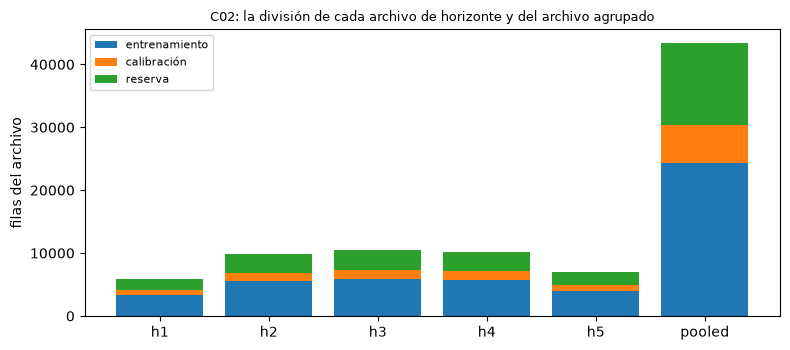

las cuatro marcas se cumplen, las filas particionan: h1 True True
las cuatro marcas se cumplen, las filas particionan: h2 True True
las cuatro marcas se cumplen, las filas particionan: h3 True True
las cuatro marcas se cumplen, las filas particionan: h4 True True
las cuatro marcas se cumplen, las filas particionan: h5 True True
las cuatro marcas se cumplen, las filas particionan: pooled True True


In [4]:
# Las filas de las partes de entrenamiento, calibración y reserva de los seis archivos de C02 y sus cuatro marcas
fig, ax = plt.subplots(figsize=(8, 3.6))
bottom = np.zeros(len(c02))
keys = ("train_rows", "calibration_rows", "holdout_rows")
parts = zip(keys, ("tab:blue", "tab:orange", "tab:green"), ["entrenamiento", "calibración", "reserva"])
for key, color, label in parts:
    values = np.array([doc["outputs"]["split"][key] for doc in c02.values()])
    ax.bar(list(c02), values, bottom=bottom, color=color, label=label)
    bottom += values
ax.set_ylabel("filas del archivo")
ax.set_title("C02: la división de cada archivo de horizonte y del archivo agrupado", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
for name, doc in c02.items():
    s, rows = doc["outputs"]["split"], doc["outputs"]["counts"]["rows"]
    flags = [s["fit_on_training_slice_only"], s["calibration_map_on_separate_slice"]]
    flags += [not s["resampling_before_calibration"], not s["out_of_time_claim"]]
    total = s["train_rows"] + s["calibration_rows"] + s["holdout_rows"]
    print("las cuatro marcas se cumplen, las filas particionan:", name, all(flags), total == rows)

Para los cinco archivos de horizonte y el archivo agrupado, las cuatro marcas se cumplen y las tres partes suman las filas del archivo. Las barras tienen la misma forma, 56%, 14% y 30% de las filas, pues se aplica a cada uno la misma división estratificada. La salvedad del archivo agrupado permanece: sin identificador de empresa, una empresa puede estar en la parte de entrenamiento de un horizonte y en la muestra reservada de otro, y las marcas del archivo agrupado no pueden decir otra cosa (notebook 05).

### Paso 3: C03, un objetivo leído solo donde es observable

C03 es el único caso con fechas, y su protocolo es fuera de tiempo: la ventana de entrenamiento cierra en la marca de 5 años de su último año de aprobación, antes de que empiece la cohorte de prueba, y el objetivo de una añada se lee solo en su propia marca de 5 años (notebook 04). Esa regla también acota los datos: una añada puede probarse solo cuando su marca de 5 años ya pasó a la fecha del archivo. El motor lleva esta regla como `check_vintage`, que rechaza una añada cuya fecha es posterior a la fecha de observación. La celda se la pregunta por las seis añadas de las dos cohortes más recientes, halla el último año de aprobación cuya marca ya pasó y pregunta por el año siguiente, donde el motor debe rechazar.

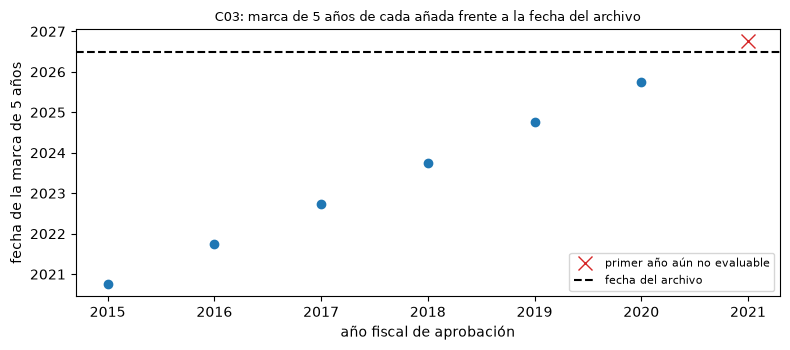

añadas aceptadas por la regla del motor: 6
último año de aprobación evaluable, y el rechazo del motor al siguiente: 2020
el motor rechaza la marca posterior a la fecha del archivo: 2026-09-30 > 2026-06-30


In [5]:
# Regla del motor sobre observabilidad: una añada con marca de 5 años posterior al archivo no puede leerse
as_of = c03_models["fit"]["data_status"]["files_as_of"]
accepted = 0
fig, ax = plt.subplots(figsize=(8, 3.6))
for name, doc in c03.items():
    for v in doc["outputs"]["vintage_summary"]["rows"]:
        check_vintage(v["five_year_mark_date"], as_of)
        accepted += 1
        mark = date.fromisoformat(v["five_year_mark_date"])
        ax.plot(v["fiscal_year"], mark.year + mark.timetuple().tm_yday / 366, "o", color="tab:blue")
last = max(fy for fy in range(1991, 2031) if date(fy + 5, 9, 30) <= date.fromisoformat(as_of))
refused_mark = f"{last + 6}-09-30"
try:
    check_vintage(refused_mark, as_of)
except ValueError:
    refused_mark = f"{refused_mark} > {as_of}"
ax.plot(last + 1, last + 6 + 0.75, "x", color="tab:red", markersize=10, label="primer año aún no evaluable")
ax.axhline(date.fromisoformat(as_of).year + 0.5, color="black", linestyle="--", label="fecha del archivo")
ax.set_xlabel("año fiscal de aprobación")
ax.set_ylabel("fecha de la marca de 5 años")
ax.set_title("C03: marca de 5 años de cada añada frente a la fecha del archivo", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("añadas aceptadas por la regla del motor:", accepted)
print("último año de aprobación evaluable, y el rechazo del motor al siguiente:", last)
print("el motor rechaza la marca posterior a la fecha del archivo:", refused_mark)

El motor acepta las seis añadas, y la figura muestra por qué: los puntos, las marcas de 5 años de AF2015 a AF2020, quedan todos bajo la línea punteada de la fecha del archivo, 2026-06-30. AF2020 es el último año de aprobación que puede probarse (su marca es 2025-09-30), y para AF2021, cuya marca sería 2026-09-30, el motor lo rechaza, y la celda imprime la marca rechazada junto a la fecha del archivo. El diseño se detiene ahí en lugar de leer un objetivo que aún no es observable, así que la última cohorte no puede terminar después de AF2020.

### Paso 4: qué no puede afirmar cada división

Un protocolo que impone reglas debe decir también dónde se detienen. Los artefactos declaran ellos mismos los límites, y la celda de carga los imprimió. C01 es una sola fotografía de 2005: el hallazgo `F-OOT`, aceptado, dice que no es posible ninguna validación fuera de tiempo. C02 fija `out_of_time_claim` en falso y etiqueta su transferencia entre archivos como exploratoria. C03 es fuera de tiempo pero es el programa de la SBA, no la cartera pyme de un banco (hallazgo `F-DATA`, aceptado). La imposición se detiene donde se detienen los datos, y lo dice.

## Comparación

Lo que halló la investigación, y dónde se detiene:

- **Las reglas son conocidas.** El dossier 04 enuncia las seis reglas anteriores para cadenas de puntuación de crédito, y el dossier 06 lista los filtros de fuga que existen en herramientas abiertas: una prueba de filtración de etiquetas, una prueba de filtración de muestras y un modelo de semejanza entre muestras de desarrollo y fuera de tiempo.
- **Se sabe que la evaluación importa.** Kozodoi, Lessmann, Alamgir, Moreira-Matias y Papakonstantinou (2025, https://doi.org/10.1016/j.ejor.2025.01.040) proponen un marco para entrenar y **evaluar** modelos de puntuación de crédito bajo sesgo de muestreo, y hallan que corregir el sesgo en la evaluación tiene un impacto de negocio mayor que en el entrenamiento. Cómo se evalúa un modelo es donde se esconden las fugas.
- **La práctica no se impone.** El dossier 07 nombra la evaluación con una sola división de una herramienta abierta como contraejemplo: una división, sin parte de calibración separada, sin declaración de lo que los datos no pueden afirmar. Las herramientas dan filtros para ejecutar; ninguna da un protocolo declarado por caso con una puerta que falla cuando se rompe.

## Evidencia

La afirmación (la lista de afirmaciones de `docs/design/SDD.md`) es esta: **el protocolo a prueba de fuga se declara por caso y se impone mediante puertas**. Es imposición de reglas conocidas, no un método nuevo, y se enuncia solo hasta donde llega la evidencia: la división de cada caso está declarada y registrada en su artefacto (pasos 1 a 3); las reglas son requisitos con una puerta con nombre; y el protocolo declara lo que no puede afirmar cada división (paso 4). Una evidencia más es cómo se ve una filtración para las pruebas, porque una puerta sobre la ruta de ajuste protege los ajustes del producto, mientras un validador frente al modelo de otro tiene solo las pruebas. El caso C22 planta una filtración de tamaño conocido: el puntaje es el puntaje genuino más una variable que **en el desarrollo lleva el resultado**, desplazada por el tamaño de la filtración para los incumplidores, y **al momento de decidir es ruido**. El generador `BinormalScores` del motor conoce el AUC exacto. La celda genera una muestra con semilla con una filtración de 1 y otra sin filtración (la nula) y llama a las pruebas de discriminación del motor sobre ambas: el AUC de la muestra de desarrollo, el AUC de ahora, y la prueba de una cola del AUC contra desarrollo (Hanley y McNeil, 1982).

In [6]:
# Una muestra con semilla con filtración 1 y otra sin ella, y el AUC contra desarrollo del motor en cada una
samples = {}
for leak in (0.0, 1.0):
    generator = BinormalScores(n_defaulters=150, n_survivors=4850, separation=1.0, leak=leak)
    sample = generator.draw(np.random.default_rng(42))
    kw = dict(policy=policy, model_id="leak")
    auc_dev = disc_auc(sample["development_risk"], sample["development_defaults"], **kw).metric
    auc_now = disc_auc(sample["risk"], sample["defaults"], **kw).metric
    drop = disc_auc_vs_initial(sample["auc_initial"], sample["risk"], sample["defaults"], **kw)
    samples[leak] = sample
    p_text = float(f"{drop.p_value:.3g}")
    print("filtración, AUC desarrollo, AUC ahora:", leak, round(auc_dev, 4), round(auc_now, 4))
    print("   p:", p_text, LIGHT[drop.light.value])

filtración, AUC desarrollo, AUC ahora: 0.0 0.6866 0.6779
   p: 0.259 verde
filtración, AUC desarrollo, AUC ahora: 1.0 0.8367 0.6779
   p: 3.95e-15 roja


Sin filtración, el AUC de desarrollo es 0,6866 y el AUC de ahora es 0,6779, y la prueba no rechaza (p de 0,259, verde). Con una filtración de 1, el AUC de desarrollo es 0,8367 y el AUC de ahora vuelve al 0,6779 genuino, una caída de 0,159 que la prueba rechaza con un valor p de 3,95e-15 (roja). La variable filtrada infló el AUC de desarrollo, y nada en la muestra de desarrollo por sí sola podía decirlo: la muestra parece un buen modelo. La prueba ve la filtración solo cuando se puntúan tarjetas con una variable que ya no lleva el resultado.

La segunda vista es la variable misma. El índice de estabilidad por característica (CSI) es el índice de estabilidad de la población de una variable de entrada, con diez tramos fijados en la muestra de desarrollo, y su valor p chi cuadrado pregunta si la variable se movió entre el desarrollo y ahora (Yurdakul y Naranjo, 2020). Una filtración hace que una variable lleve el resultado en el desarrollo y sea ruido ahora, de modo que su distribución puede desplazarse solo para los incumplidores, y el desplazamiento depende de cuántos incumplidores haya. La celda ejecuta `quantile_edges`, `bin_counts` y `stability_csi` sobre las mismas dos muestras.

In [7]:
# La estabilidad por característica del motor para la variable filtrada en las mismas dos muestras, diez tramos fijos
for leak, sample in samples.items():
    edges = quantile_edges(sample["feature_development"], 10)
    expected = bin_counts(sample["feature_development"], edges)
    actual = bin_counts(sample["feature_current"], edges)
    csi = stability_csi(expected, actual, policy=policy, model_id="leak", segment="leaked feature")
    print("filtración, valor p del CSI y luz:", leak, round(csi.p_value, 3), LIGHT[csi.light.value])

filtración, valor p del CSI y luz: 0.0 0.24 verde
filtración, valor p del CSI y luz: 1.0 0.046 ámbar


El valor p del CSI es 0,24 sin filtración (verde) y 0,046 con ella (ámbar): la estabilidad de la variable filtrada casi no reacciona, que es la primera señal de que es el lugar equivocado para buscar una filtración. Una muestra dice poco, sin embargo, pues ambos números se mueven con la semilla. La siguiente celda mide la afirmación: para cada uno de seis tamaños de filtración genera 300 muestras con semillas de 1000 a 1299, ejecuta el AUC contra desarrollo y el CSI sobre cada una, y cuenta con qué frecuencia cada una rechaza al 5%. Con filtración 0 la tasa es el tamaño de la prueba y debe estar cerca de 0,05; sobre 0 es la potencia. Con 300 repeticiones el error estándar de Monte Carlo de una tasa cercana a un medio es de cerca de 0,03, así que la celda guarda las tasas y la siguiente figura les pone las barras de error.

In [8]:
# Monte Carlo de la afirmación: con qué frecuencia rechaza cada prueba al 5%, por tamaño de filtración, con semillas
leaks = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0]
n_rep = 300
rates = {}
for leak in leaks:
    generator = BinormalScores(n_defaulters=150, n_survivors=4850, separation=1.0, leak=leak)
    hits = np.zeros(2)
    for rep in range(n_rep):
        s = generator.draw(np.random.default_rng(1000 + rep))
        drop = disc_auc_vs_initial(s["auc_initial"], s["risk"], s["defaults"], policy=policy, model_id="leak")
        edges = quantile_edges(s["feature_development"], 10)
        shift = stability_csi(bin_counts(s["feature_development"], edges), bin_counts(s["feature_current"], edges),
                              policy=policy, model_id="leak", segment="leaked feature")
        hits += [drop.p_value < 0.05, shift.p_value < 0.05]
    rates[leak] = hits / n_rep
print("repeticiones por tamaño de filtración:", n_rep)
table = {leak: np.round(r, 3).tolist() for leak, r in rates.items()}
print("tasas de rechazo por filtración (prueba de AUC, CSI):", table)

repeticiones por tamaño de filtración: 300
tasas de rechazo por filtración (prueba de AUC, CSI): {0.0: [0.047, 0.053], 0.25: [0.61, 0.06], 0.5: [0.993, 0.083], 1.0: [1.0, 0.167], 1.5: [1.0, 0.4], 2.0: [1.0, 0.667]}


Sin filtración, la prueba de AUC rechaza en 0,047 de las repeticiones y el CSI en 0,053, ambos cerca del 0,05 nominal: las pruebas conservan su tamaño. Con una filtración de 0,25 la prueba de AUC rechaza en 0,61, con 0,5 en 0,993 y desde 1 en todas, mientras el CSI pasa de 0,06 en 0,25 a 0,083, 0,167, 0,4 y 0,667 en 0,5, 1, 1,5 y 2. Visto donde un validador puede mirar, una filtración es una caída de discriminación fuera de tiempo mucho antes de ser una deriva de la variable. La figura dibuja estas tasas con su error de Monte Carlo junto a las tasas de 2.000 repeticiones versionadas en C22: los puntos de la prueba de AUC siguen la curva versionada, y los del CSI quedan sobre ella en las filtraciones grandes, como dice el párrafo siguiente.

### El tamaño de la inflación

El generador conoce también la verdad exactamente. Para cada tamaño de filtración su `truth()` devuelve el AUC de la muestra de desarrollo, en forma cerrada para el modelo binormal, y el AUC del puntaje genuino ahora. La diferencia es la inflación que una filtración agrega al número que citaría un informe de desarrollo, y la razón de que la prueba anterior tenga algo que ver. La celda la calcula para los seis tamaños de filtración y dibuja la curva.

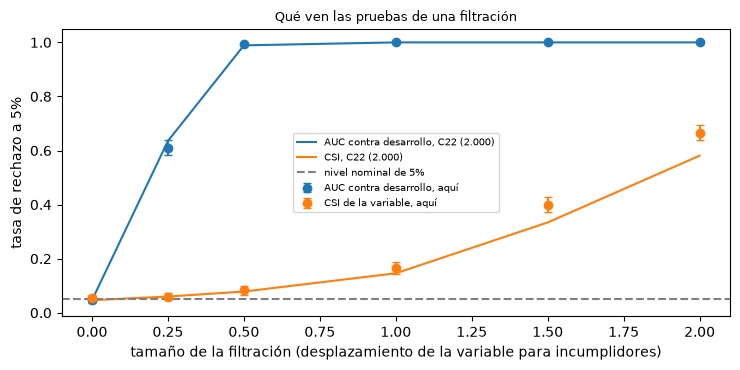

ejemplar versionado, filtración 1, p (AUC, CSI): 4.56e-16 0.639


In [9]:
# Las tasas de este notebook frente a las versionadas en C22 (2000 repeticiones), con el error de Monte Carlo
sims = {s["key"]: s for s in c22["outputs"]["simulations"]}
committed = {kind: [sims[f"{kind}@l{x:g}"]["rates"]["p<0.05"]["rate"] for x in leaks] for kind in
             ("disc.auc_vs_initial", "stability.csi")}
fig, ax = plt.subplots(figsize=(7.5, 3.8))
panels = [
    (0, "disc.auc_vs_initial", "AUC contra desarrollo, aquí", "AUC contra desarrollo, C22 (2.000)", "tab:blue"),
    (1, "stability.csi", "CSI de la variable, aquí", "CSI, C22 (2.000)", "tab:orange"),
]
for column, kind, label, line_label, color in panels:
    own = np.array([rates[x][column] for x in leaks])
    ax.errorbar(leaks, own, yerr=np.sqrt(own * (1 - own) / n_rep), fmt="o", color=color, capsize=3, label=label)
    ax.plot(leaks, committed[kind], color=color, linestyle="-", label=line_label)
ax.axhline(0.05, color="gray", linestyle="--", label="nivel nominal de 5%")
ax.set_xlabel("tamaño de la filtración (desplazamiento de la variable para incumplidores)")
ax.set_ylabel("tasa de rechazo a 5%")
ax.set_title("Qué ven las pruebas de una filtración", fontsize=9)
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()
specimen = {t["test_id"]: t for t in c22["tests"]}
p_auc = float(f"{specimen['disc.auc_vs_initial']['p_value']:.3g}")
print("ejemplar versionado, filtración 1, p (AUC, CSI):", p_auc, round(specimen["stability.csi"]["p_value"], 3))

La figura respalda la lectura anterior. En 0,25 la prueba de AUC rechaza en 0,61 de las repeticiones y la simulación coincide con el 0,635 versionado dentro de su error, y con filtración 1 ambas son 1,0; los puntos del CSI del notebook quedan sobre la curva versionada en las filtraciones grandes (0,4 contra 0,334 en 1,5, cerca de dos errores estándar de Monte Carlo de 300 repeticiones); el notebook no explica la diferencia más allá de sus semillas y de sus 300 repeticiones frente a las 2.000 de C22, y la lectura es la misma. El ejemplar versionado de C22, un solo sorteo con filtración 1, da p de 4,56e-16 para la prueba de AUC y 0,639 para el CSI (verde), un recordatorio de cuán poco dice una muestra de la variable. El alza lenta del CSI significa que un validador que vigile solo la estabilidad de las entradas vería tarde una filtración, y un constructor de modelos que cuente con eso no tiene protección.

### La inflación exacta

Con la afirmación medida, la celda siguiente muestra de qué está hecha: el AUC de desarrollo que produce la filtración, frente al AUC que daría el puntaje genuino en tarjetas nuevas.

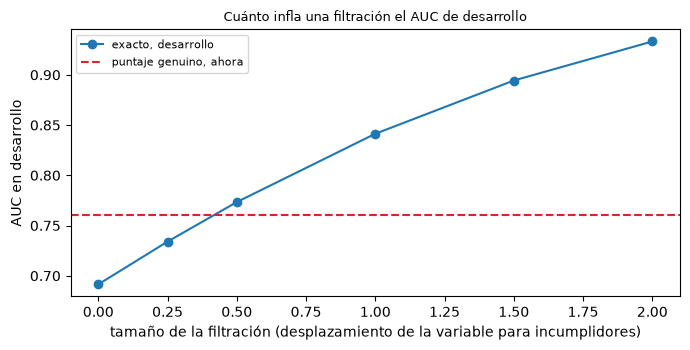

AUC exacto de desarrollo con filtración 1, AUC genuino ahora: 0.8413 0.7602
inflación exacta del AUC de desarrollo por una filtración de 1: 0.1499


In [10]:
# El AUC de desarrollo exacto que conoce el generador para cada filtración, frente al AUC del puntaje genuino ahora
exact = [BinormalScores(n_defaulters=150, n_survivors=4850, separation=1.0, leak=x).truth() for x in leaks]
development = [t["auc_development"] for t in exact]
genuine = exact[0]["auc_genuine_current"]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(leaks, development, marker="o", label="exacto, desarrollo")
ax.axhline(genuine, color="tab:red", linestyle="--", label="puntaje genuino, ahora")
ax.set_xlabel("tamaño de la filtración (desplazamiento de la variable para incumplidores)")
ax.set_ylabel("AUC en desarrollo")
ax.set_title("Cuánto infla una filtración el AUC de desarrollo", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("AUC exacto de desarrollo con filtración 1, AUC genuino ahora:", round(development[3], 4), round(genuine, 4))
print("inflación exacta del AUC de desarrollo por una filtración de 1:", round(development[3] - development[0], 4))

## Resultados

**Respuesta:** Las pruebas de validación ven una filtración como una caída de discriminación fuera de tiempo, mucho antes de verla como una deriva de la variable, y el protocolo la detiene antes del ajuste y no después. En la medición de este notebook, con 300 repeticiones con semilla por tamaño de filtración, el AUC contra desarrollo rechaza al 5% en 0,047 de las muestras sin filtración (su tamaño), 0,61 con una filtración de 0,25, 0,993 con 0,5 y 1,0 desde 1, mientras el índice de estabilidad por característica de la variable filtrada rechaza en 0,053, 0,06, 0,083, 0,167, 0,4 y 0,667 con filtraciones de 0, 0,25, 0,5, 1, 1,5 y 2. La causa es exacta: una filtración de 1 infla el AUC de desarrollo desde 0,7602, el del puntaje genuino, a 0,8413, una inflación de 0,1499. Para el protocolo, los tres requisitos CT-101 a CT-103 nombran sus puertas; C01 tiene 16.800 tarjetas detrás de cada una de sus 13 variables agrupadas y sus tres mapas de calibración se ajustaron con la parte de calibración; las cuatro marcas se cumplen y las filas particionan en los seis archivos de C02; y en C03 el motor acepta las 6 añadas de las dos cohortes más recientes y rechaza una añada cuya marca de 5 años (2026-09-30) es posterior al archivo (2026-06-30), de modo que AF2020 es el último año evaluable.

Lo que la afirmación enuncia es la imposición de reglas conocidas, caso por caso, con una puerta que falla y una declaración de lo que no puede afirmar cada división; no es un método nuevo, y este notebook no ejecuta las puertas (requieren las bibliotecas de la cadena de cálculo). La filtración plantada es sintética y de un solo tipo, una variable que lleva el resultado en el desarrollo; una filtración por tiempo, un valor fechado después de la fecha de observación, la cubren la puerta CT-103 y la regla del motor sobre añadas, no esta demostración. El marco de evaluación de Kozodoi et al. (2025) aborda otro problema, el sesgo de muestreo de solicitantes aceptados y rechazados.

## Resumen

- La afirmación: el protocolo a prueba de fuga se declara por caso y se impone mediante puertas. Las reglas son conocidas (dossier 04); el producto agrega una prueba con nombre que falla para cada una (CT-101 a CT-103) y una división declarada y registrada para cada caso.
- En los artefactos versionados se cumple lo que garantizan las puertas: conteos solo de la parte de entrenamiento, calibración con su propia parte, marcas que rechazan una afirmación fuera de tiempo, y un objetivo leído solo donde es observable, con el motor rechazando la añada que no lo es.
- El protocolo declara lo que no puede afirmar cada división: C01 no tiene validación fuera de tiempo, C02 no hace afirmaciones fuera de tiempo, C03 es un programa federal.
- Medida por simulación y frente a la verdad exacta del generador, una filtración la ven las pruebas como una caída de discriminación fuera de tiempo y solo tarde como una deriva de la variable, y por eso hay que detenerla antes del ajuste.

**Qué probar a continuación.** Cambia la separación del generador en la sección Evidencia y mira cómo se mueve la potencia de la prueba de AUC contra desarrollo; lee `tests/test_leakage.py` y ejecútalo en el entorno de la cadena de cálculo (`python -m pytest tests/test_leakage.py`); luego continúa con los otros temas, que aplican la misma disciplina a sus propios casos.

## Referencias

- Mavin, A., Wilkinson, P., Harwood, A. y Novak, M. (2009), Easy Approach to Requirements Syntax (EARS), 17th IEEE International Requirements Engineering Conference. https://doi.org/10.1109/RE.2009.9
- Kozodoi, N., Lessmann, S., Alamgir, M., Moreira-Matias, L. y Papakonstantinou, K. (2025), Fighting sampling bias: a framework for training and evaluating credit scoring models, European Journal of Operational Research 324(2). https://doi.org/10.1016/j.ejor.2025.01.040
- Hanley, J. A. y McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sección 2.5.4.1 y Anexo 3.1. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Yurdakul, B. y Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- U.S. Small Business Administration, 7(a) and 504 FOIA loan data (U.S. Government Works). https://data.sba.gov/dataset/7a-504-foia
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients ; Tomczak, S. (2016), Polish Companies Bankruptcy, UCI (CC BY 4.0). https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data
- Este repositorio: los dossiers 04, 06 y 07 de la base de investigación (`docs/design/SDD.md`), `docs/design/features/c01-retail-pd/requirements.md`, `tests/test_leakage.py`.